<a href="https://colab.research.google.com/github/buabns/Aulas_PCD/blob/main/PROJETO_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Importação de Bibliotecas e Dados

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path


caminho_arquivo = "/content/drive/MyDrive/steam-200k.csv.zip"

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Ambiente fora do Google Colab: verifique o caminho do arquivo.")

if not Path(caminho_arquivo).exists():
    raise FileNotFoundError(
        f"Arquivo não encontrado: {caminho_arquivo}. "
        "Ajuste caminho_arquivo para o local correto do CSV ou ZIP."
    )

df = pd.read_csv(caminho_arquivo, low_memory=False)

display(df.head())

Mounted at /content/drive


,151603712,The Elder Scrolls V Skyrim,purchase,1.0,0
0,151603712,The Elder Scrolls V Skyrim,play,273.0,0
1,151603712,Fallout 4,purchase,1.0,0
2,151603712,Fallout 4,play,87.0,0
3,151603712,Spore,purchase,1.0,0
4,151603712,Spore,play,14.9,0


In [3]:
#Verifica os nomes atuais das colunas e o tamanho do dataset
print("Colunas atuais:", df.columns.tolist())
print("Tamanho inicial:", df.shape)

#Se as colunas estiverem estranhas (ex: com números ou nomes de jogos na primeira linha),
#recarregue o arquivo passando os nomes corretos:
df = pd.read_csv(caminho_arquivo, header=None, names=['user_id', 'game_name', 'behavior', 'hours', 'other'])
df = df.drop(columns=['other']) #Remove a última coluna inútil que costuma vir no csv

display(df.head())

Colunas atuais: ['151603712', 'The Elder Scrolls V Skyrim', 'purchase', '1.0', '0']
Tamanho inicial: (199999, 5)


,user_id,game_name,behavior,hours
0,151603712,The Elder Scrolls V Skyrim,purchase,1.0
1,151603712,The Elder Scrolls V Skyrim,play,273.0
2,151603712,Fallout 4,purchase,1.0
3,151603712,Fallout 4,play,87.0
4,151603712,Spore,purchase,1.0


# 2. Limpeza e Filtragem dos Dados

In [4]:
#Mantém apenas as linhas onde o usuário efetivamente jogou
df_play = df[df['behavior'] == 'play'].copy()

#Remove a coluna 'behavior' pois agora ela é redundante (todos são 'play')
df_play = df_play.drop(columns=['behavior'])

print("Tamanho após filtrar 'play':", df_play.shape)

display(df_play.head())

Tamanho após filtrar 'play': (70489, 3)


,user_id,game_name,hours
1,151603712,The Elder Scrolls V Skyrim,273.0
3,151603712,Fallout 4,87.0
5,151603712,Spore,14.9
7,151603712,Fallout New Vegas,12.1
9,151603712,Left 4 Dead 2,8.9


In [5]:
#Verifica se há valores nulos nas colunas cruciais
print("\nValores nulos por coluna:")
print(df_play.isnull().sum())


Valores nulos por coluna:
user_id      0
game_name    0
hours        0
dtype: int64


In [19]:
#Exclui horas jogadas irrelevantes (ex: menos de 30 minutos)
limite_minimo_horas = 0.5
df_play = df_play[df_play['hours'] >= limite_minimo_horas]

In [20]:
#Remove linhas completamente duplicadas (se o sistema da Steam falhou e registrou 2x)
df_play = df_play.drop_duplicates()

print("Tamanho após limpeza final:", df_play.shape)
display(df_play.head())

Tamanho após limpeza final: (61040, 4)


,user_id,game_name,hours,hours_weight
1,151603712,The Elder Scrolls V Skyrim,273.0,5.613128
3,151603712,Fallout 4,87.0,4.477337
5,151603712,Spore,14.9,2.766319
7,151603712,Fallout New Vegas,12.1,2.572612
9,151603712,Left 4 Dead 2,8.9,2.292535


In [8]:
import numpy as np

# Aplicando o Log-Transform nas horas jogadas
df_play['hours_weight'] = np.log1p(df_play['hours'])

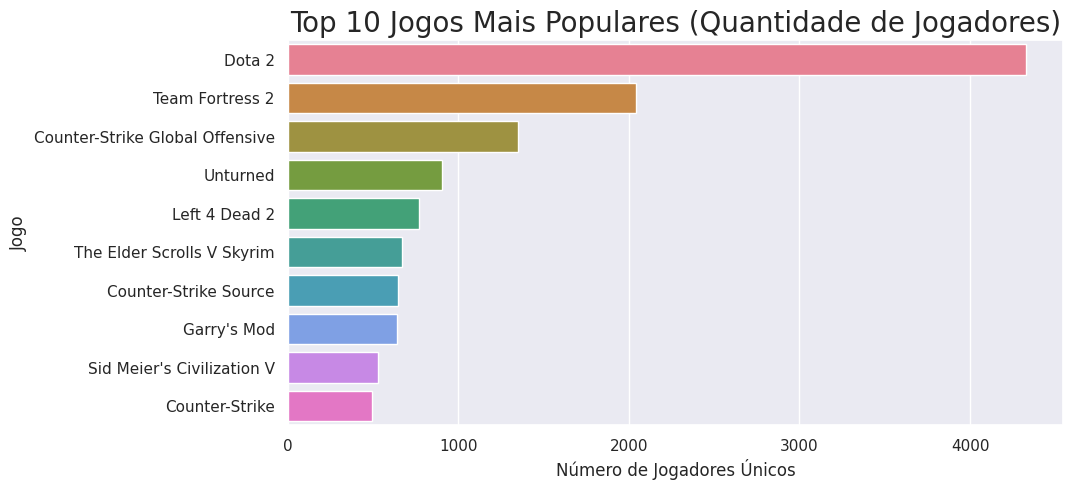

In [9]:

# Configuração visual padrão para os gráficos ficarem com cara de projeto profissional
sns.set_theme(style="darkgrid", palette="viridis")

# 1. Os 10 Jogos Mais Populares (por número de jogadores)
top_jogos_jogadores = df_play['game_name'].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_jogos_jogadores.values, y=top_jogos_jogadores.index, hue=top_jogos_jogadores.index,)
plt.title('Top 10 Jogos Mais Populares (Quantidade de Jogadores)', fontsize=20)
plt.xlabel('Número de Jogadores Únicos')
plt.ylabel('Jogo')
plt.show()



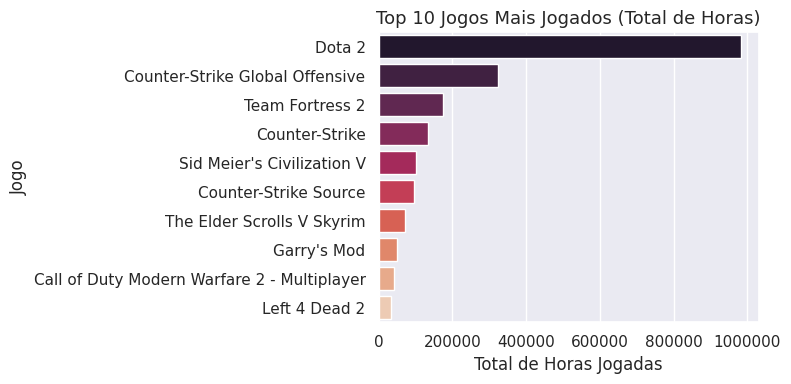

In [10]:
# 2. Os 10 Jogos Mais Jogados (por total de horas acumuladas)
top_jogos_horas = df_play.groupby('game_name')['hours'].sum().sort_values(ascending=False).head(10)

# Reduzido de (10, 5) para (8, 4)
plt.figure(figsize=(8, 4))
sns.barplot(x=top_jogos_horas.values, y=top_jogos_horas.index, hue=top_jogos_horas.index, palette="rocket", legend=False)
plt.ticklabel_format(style='plain', axis='x')
plt.title('Top 10 Jogos Mais Jogados (Total de Horas)', fontsize=13)
plt.xlabel('Total de Horas Jogadas')
plt.ylabel('Jogo')
plt.tight_layout()
plt.show()

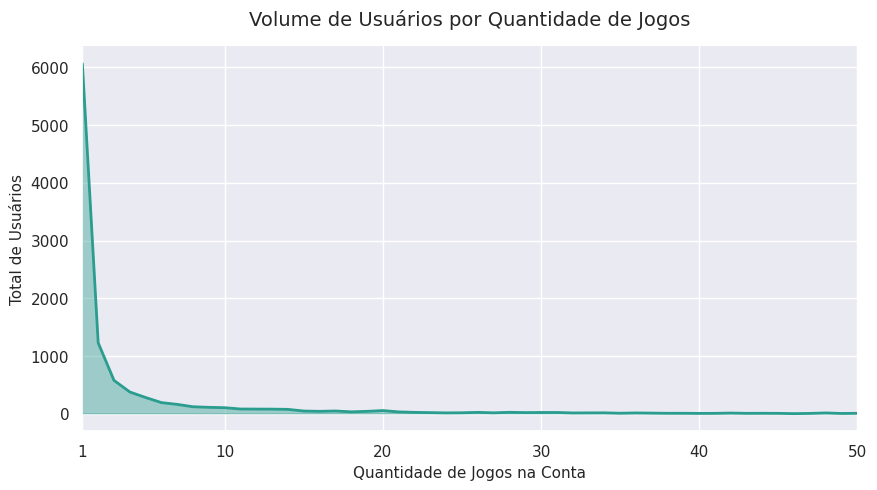

In [11]:
# Calcula a distribuição de quantidade de jogos por usuário
jogos_por_usuario = df_play.groupby('user_id')['game_name'].count()
distribuicao = jogos_por_usuario.value_counts().sort_index()

plt.figure(figsize=(10, 5))

# Desenha a montanha
plt.fill_between(distribuicao.index, distribuicao.values, color='#2a9d8f', alpha=0.4)
plt.plot(distribuicao.index, distribuicao.values, color='#2a9d8f', linewidth=2)

# O ajuste do zero: Começa no 1, e marca os próximos de 10 em 10
plt.xlim(1, 50)
plt.xticks([1, 10, 20, 30, 40, 50])

plt.title('Volume de Usuários por Quantidade de Jogos', fontsize=14, pad=15)
plt.xlabel('Quantidade de Jogos na Conta', fontsize=11)
plt.ylabel('Total de Usuários', fontsize=11)

sns.despine()
plt.show()

In [14]:

from sklearn.neighbors import NearestNeighbors

# 1. Cria a Matriz Pivot (Isso pode demorar alguns segundos dependendo do PC)
# Substitui os valores nulos (jogos que o usuário não jogou) por 0
matriz_jogos_usuarios = df_play.pivot_table(index='game_name', columns='user_id', values='hours_weight').fillna(0)


print("Formato da Matriz:", matriz_jogos_usuarios.shape)
# O resultado mostrará (Número de Jogos, Número de Usuários)

Formato da Matriz: (3302, 10448)


In [15]:
# 3. Configuração do Modelo KNN
# metric='cosine': Mede o ângulo entre os vetores de horas jogadas (excelente para recomendação)
# n_neighbors=6: Pega o jogo em si (1) + as 5 melhores recomendações (5)
modelo_knn = NearestNeighbors(metric='cosine', algorithm='brute', n_neighbors=6)

# 4. Treinamento
modelo_knn.fit(matriz_jogos_usuarios)
print("Modelo treinado com sucesso!")

Modelo treinado com sucesso!


In [21]:
nome_do_jogo = input("\nDigite o nome do jogo: ")
def recomendar_jogos(nome_do_jogo, modelo, matriz, n_recomendacoes=5):
    # Verifica se o jogo existe na base de dados
    if nome_do_jogo not in matriz.index:
        return f"O jogo '{nome_do_jogo}' não foi encontrado na base de dados ou foi escrito de forma errada."

    # Encontra a posição (índice numérico) do jogo na matriz
    indice_jogo = matriz.index.get_loc(nome_do_jogo)

    # Pega as distâncias e os índices dos vizinhos mais próximos
    # reshape(1, -1) é exigência do scikit-learn para passar uma única linha
    distancias, indices = modelo.kneighbors(matriz.iloc[indice_jogo, :].values.reshape(1, -1))
    print(f"Porque você jogou ** {nome_do_jogo} **, recomendamos:\n")

    # O primeiro resultado (índice 0) é o próprio jogo, então começamos do 1
    for i in range(1, len(distancias.flatten())):
        jogo_recomendado = matriz.index[indices.flatten()[i]]
        distancia = distancias.flatten()[i]

        # Quanto menor a distância, maior a similaridade
        print(f"{i}. {jogo_recomendado} (Distância: {distancia:.3f})")

# TESTE NA HORA DA APRESENTAÇÃO
# Troque 'Portal 2' ou 'Dota 2' por jogos que vocês sabem que existem na base
recomendar_jogos(nome_do_jogo, modelo_knn, matriz_jogos_usuarios)


Digite o nome do jogo: Portal 2
Porque você jogou ** Portal 2 **, recomendamos:

1. Portal (Distância: 0.469)
2. Left 4 Dead 2 (Distância: 0.648)
3. Half-Life 2 (Distância: 0.651)
4. Borderlands 2 (Distância: 0.659)
5. The Elder Scrolls V Skyrim (Distância: 0.690)
